In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)

In [2]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import slmsuite

from slmsuite.hardware.slms.meadowlark import Meadowlark
from slmsuite.hardware.cameras.alliedvision import AlliedVision
from slmsuite.hardware.cameraslms import FourierSLM

from slmsuite.holography.algorithms import SpotHologram
from slmsuite.holography import analysis


print("slmsuite version:", slmsuite.__version__)
print("Imports successful.")

slmsuite version: 0.4.1
Imports successful.


c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [3]:
# ============================================================
# PATHS
# ============================================================

SDK_PATH = Path(
    r"C:\Program Files\Meadowlark Optics\Blink 1920 HDMI\SDK"
)

LUT_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Experiment scripts"
    r"\LUT_locked_759nm_20260811_201109\759nm_KS_global_20260811.lut"
)

FOURIER_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\After M change"
    r"\YDFC_fourier_300-1000_plus16_pre-wavefront_00000.h5"
)


print("SDK exists     :", SDK_PATH.exists())
print("LUT exists     :", LUT_PATH.exists())
print("Fourier exists :", FOURIER_PATH.exists())

SDK exists     : True
LUT exists     : True
Fourier exists : True


In [4]:
# ============================================================
# INITIALIZE SLM
# ============================================================

slm = Meadowlark(
    slm_number=1,
    sdk_path=str(SDK_PATH),
    lut_path=str(LUT_PATH),
    wav_um=0.7593,
    verbose=True,
)


print("\n=== SLM READY ===")
print("Name       :", slm.name)
print("Shape      :", slm.shape)
print("Wavelength :", slm.wav_um, "um")
print("Pixel pitch:", slm.pitch_um, "um")

Validating DPI awareness...success
Constructing Blink SDK...success
Loading LUT file...
=== SLM READY ===
Name       : Meadowlark HDMI
Shape      : (1200, 1920)
Wavelength : 0.7593 um
Pixel pitch: [8. 8.] um


In [5]:
# ============================================================
# INITIALIZE ALLIED VISION CAMERA
# ============================================================

CAMERA_SERIAL = "015C2"

cam = AlliedVision(
    serial=CAMERA_SERIAL,
    verbose=True,
)


print("\n=== CAMERA READY ===")
print("Shape     :", cam.shape)
print("WOI       :", cam.woi)
print("Exposure  :", cam.exposure_s, "s")
print("Bit depth :", cam.bitdepth)

vmbpy initializing... success
Looking for cameras... success
vmbpy sn '015C2' initializing... success

=== CAMERA READY ===
Shape     : (3672, 5496)
WOI       : (0, 5496, 0, 3672)
Exposure  : 2.9681000000000003e-05 s
Bit depth : 8


c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\hardware\cameras\camera.py:444: UserWarning: '015C2' _get_image_hw() failed 5 times before quitting.
  warnings.warn(f"'{self.name}' _get_image_hw() failed {failures} times before quitting.")


In [6]:
# ============================================================
# CREATE FOURIER SLM AND LOAD NEW 300/1000 CALIBRATION
# ============================================================

fs = FourierSLM(
    cam,
    slm
)


loaded_path = fs.load_calibration(
    "fourier",
    str(FOURIER_PATH)
)


print("Loaded calibration:")
print(loaded_path)

print("\nCalibration keys:")
print(fs.calibrations.keys())

fourier = fs.calibrations["fourier"]

print("\nM =")
print(fourier["M"])

print("\nb =")
print(fourier["b"])

print("\na =")
print(fourier["a"])

Loaded calibration:
C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\After M change\YDFC_fourier_300-1000_plus16_pre-wavefront_00000.h5

Calibration keys:
dict_keys(['fourier'])

M =
[[ 127279.73025868     293.23159981]
 [    450.42127708 -125110.53609542]]

b =
[[2799.33492288]
 [1157.53158414]]

a =
[[5.93203125e-03]
 [5.63221908e-20]]


In [7]:
# ============================================================
# VERIFY CALIBRATION MAPPING
# ============================================================

# Zeroth order
kxy_zero = np.array([
    0.0,
    0.0
])

# A 16-SLM-pixel blaze at 759.3 nm with 8 um SLM pixels:
#
# lambda / (16 * pixel_pitch)
#
# = 0.7593 um / (16 * 8 um)
# = 0.00593203125

kxy_carrier = np.array([
    0.00593203125,
    0.0
])


ij_zero = np.asarray(
    fs.kxyslm_to_ijcam(kxy_zero)
).reshape(2, -1)[:, 0]

ij_carrier = np.asarray(
    fs.kxyslm_to_ijcam(kxy_carrier)
).reshape(2, -1)[:, 0]


print("ZERO ORDER:")
print(ij_zero)

print("\n+16 px carrier:")
print(ij_carrier)

print("\nCarrier displacement [camera px]:")
print(ij_carrier - ij_zero)

ZERO ORDER:
[2044.3075855  1154.85967105]

+16 px carrier:
[2799.33492288 1157.53158414]

Carrier displacement [camera px]:
[755.02733739   2.67191309]


In [8]:
# ============================================================
# LOAD OLD WAVEFRONT CORRECTION
# ============================================================

from pathlib import Path
import numpy as np


WAVEFRONT_PHASE_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts"
    r"\YDFC_wavefront_phase_processed_R2p80_50ms_dark.npy"
)


print("Wavefront file exists:", WAVEFRONT_PHASE_PATH.exists())


wavefront_phase = np.load(
    WAVEFRONT_PHASE_PATH
)


print("\nWavefront correction:")
print("Shape       :", wavefront_phase.shape)
print("SLM shape   :", slm.shape)
print("Min phase   :", np.nanmin(wavefront_phase))
print("Max phase   :", np.nanmax(wavefront_phase))
print("All finite? :", np.all(np.isfinite(wavefront_phase)))


assert wavefront_phase.shape == slm.shape, \
    "Wavefront phase shape does not match SLM!"

Wavefront file exists: True

Wavefront correction:
Shape       : (1200, 1920)
SLM shape   : (1200, 1920)
Min phase   : 0.0
Max phase   : 6.2831762207757835
All finite? : True


In [9]:
# ============================================================
# INSTALL WAVEFRONT CORRECTION INTO SLM SOURCE
# ============================================================

slm.source["phase"] = wavefront_phase.copy()


print("SLM source keys:")
print(slm.source.keys())

print("\nWavefront correction installed:")
print("phase" in slm.source)

SLM source keys:
dict_keys(['phase'])

Wavefront correction installed:
True


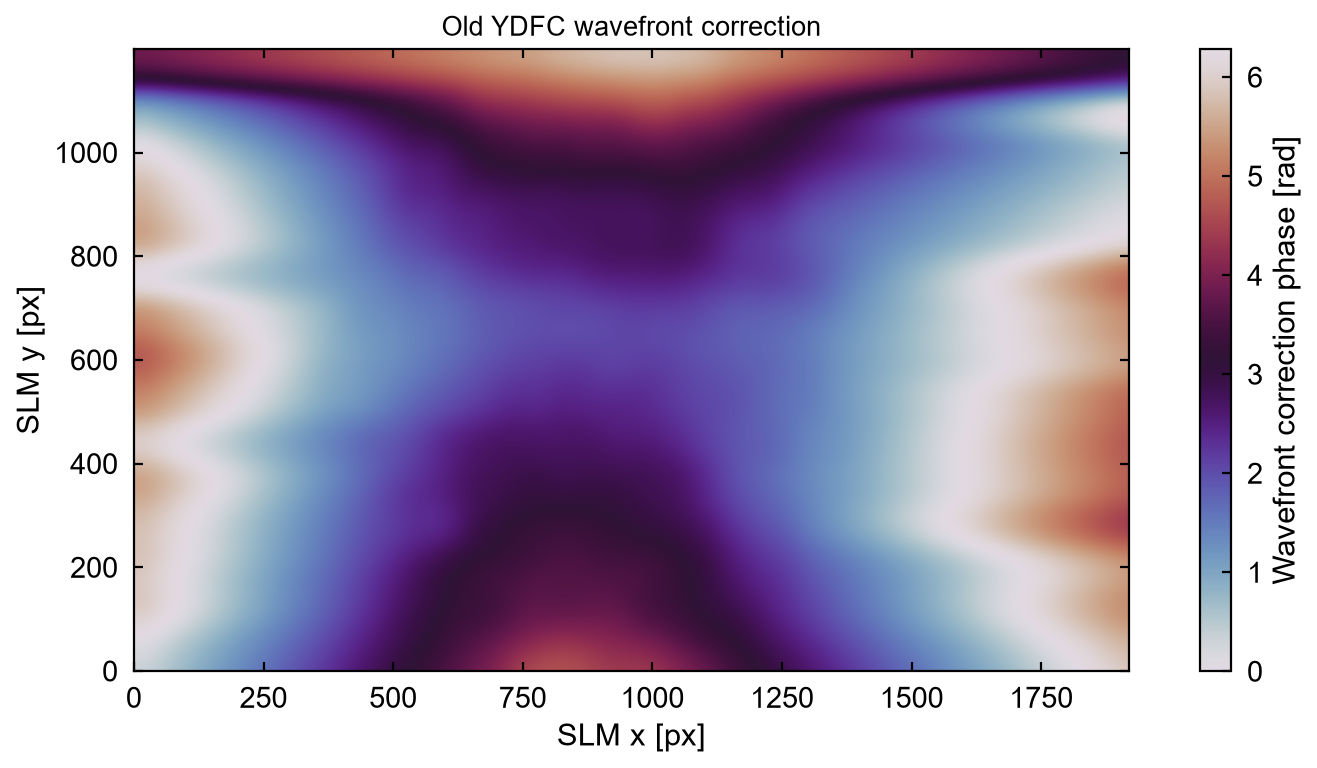

In [10]:
plt.figure(figsize=(10, 5))

plt.imshow(
    wavefront_phase,
    cmap="twilight",
    origin="lower",
)

plt.colorbar(
    label="Wavefront correction phase [rad]"
)

plt.xlabel("SLM x [px]")
plt.ylabel("SLM y [px]")
plt.title("Old YDFC wavefront correction")

plt.tight_layout()
plt.show()

In [11]:
print("Wavefront correction active in source:")
print("phase" in slm.source)

print("\nCorrection shape:")
print(slm.source["phase"].shape)

print("\nCorrection range:")
print(
    np.min(slm.source["phase"]),
    np.max(slm.source["phase"])
)

Wavefront correction active in source:
True

Correction shape:
(1200, 1920)

Correction range:
0.0 6.2831762207757835


In [12]:
# ============================================================
# 2x2 TWEEZER TARGET
# ============================================================

ATOM_SPACING_UM = 5.0

F_L2_MM = 1000.0
F_OBJ_MM = 26.9

CAM_PIXEL_UM = 2.4


# 5 um at atom plane -> Allied Vision camera pixels
CAMERA_PITCH_PX = (
    ATOM_SPACING_UM
    * F_L2_MM
    / F_OBJ_MM
    / CAM_PIXEL_UM
)


# Center on calibrated +16-pixel carrier
ARRAY_CENTER_IJ = ij_carrier.copy()


print("Desired atom spacing      :", ATOM_SPACING_UM, "um")
print("Predicted camera spacing  :", CAMERA_PITCH_PX, "px")

print("\nArray center [camera px]:")
print(ARRAY_CENTER_IJ)

Desired atom spacing      : 5.0 um
Predicted camera spacing  : 77.44733581164809 px

Array center [camera px]:
[2799.33492288 1157.53158414]


In [13]:
# ============================================================
# CREATE 2x2 SPOT HOLOGRAM
# ============================================================

NY_FFT = 2048
NX_FFT = 2048


holo_2x2 = SpotHologram.make_rectangular_array(
    shape=(NY_FFT, NX_FFT),

    array_shape=(2, 2),

    array_pitch=(
        CAMERA_PITCH_PX,
        CAMERA_PITCH_PX
    ),

    array_center=ARRAY_CENTER_IJ,

    basis="ij",

    cameraslm=fs,
)


print("2x2 hologram created.")

print("\nTarget camera coordinates:")
print(holo_2x2.spot_ij)

print("\nRounded target camera coordinates:")
print(holo_2x2.spot_ij_rounded)

print("\nCorresponding knm coordinates:")
print(holo_2x2.spot_knm)

2x2 hologram created.

Target camera coordinates:
[[2760.61125498 2838.05859079 2760.61125498 2838.05859079]
 [1118.80791624 1118.80791624 1196.25525205 1196.25525205]]

Rounded target camera coordinates:
[[2758.13949203 2840.72060706 2757.9492387  2840.53035373]
 [1116.79861024 1117.09085073 1197.97231756 1198.26455805]]

Corresponding knm coordinates:
[[1145.41983358 1158.54939362 1145.45060638 1158.58016642]
 [1030.6549672  1030.70223606 1017.29776394 1017.3450328 ]]


In [14]:
# ============================================================
# CHECK SPOT SEPARATIONS
# ============================================================

spots_pred = np.asarray(
    holo_2x2.spot_ij_rounded
)

print("Predicted spot positions:")
print(spots_pred)


print("\nPairwise distances:")

for i in range(4):
    for j in range(i + 1, 4):

        d = np.linalg.norm(
            spots_pred[:, i]
            -
            spots_pred[:, j]
        )

        print(
            f"{i} -> {j}: {d:.3f} px"
        )

Predicted spot positions:
[[2758.13949203 2840.72060706 2757.9492387  2840.53035373]
 [1116.79861024 1117.09085073 1197.97231756 1198.26455805]]

Pairwise distances:
0 -> 1: 82.582 px
0 -> 2: 81.174 px
0 -> 3: 115.866 px
1 -> 2: 115.728 px
1 -> 3: 81.174 px
2 -> 3: 82.582 px


In [15]:
# ============================================================
# BASIC GS OPTIMIZATION
# ============================================================

holo_2x2.optimize(
    method="GS",
    maxiter=20,
    verbose=True,
)


phase_2x2_gs = holo_2x2.get_phase().copy()


print("\nGS complete.")
print("Phase shape:", phase_2x2_gs.shape)
print(
    "Phase range:",
    np.nanmin(phase_2x2_gs),
    np.nanmax(phase_2x2_gs)
)

  0%|          | 0/20 [00:00<?, ?it/s]


GS complete.
Phase shape: (1200, 1920)
Phase range: 4.2915344e-06 6.283184


In [16]:
slm.source["phase"]

array([[0.35191839, 0.35029168, 0.34889027, ..., 5.91796402, 5.91606217,
        5.91426854],
       [0.34870129, 0.34707457, 0.34567316, ..., 5.91473323, 5.91283138,
        5.91103776],
       [0.34546351, 0.34383679, 0.34243539, ..., 5.91145445, 5.90955259,
        5.90775897],
       ...,
       [3.86045336, 3.85877545, 3.85722053, ..., 3.15191903, 3.15008663,
        3.14831616],
       [3.85814599, 3.85646808, 3.85491315, ..., 3.14946287, 3.14763046,
        3.14585999],
       [3.85523907, 3.85356115, 3.85200622, ..., 3.14650629, 3.14467387,
        3.1429034 ]], shape=(1200, 1920))

In [17]:
# ============================================================
# DISPLAY 2x2 WITH WAVEFRONT CORRECTION
# ============================================================

print(
    "Wavefront correction active:",
    "phase" in slm.source
)


slm.set_phase(
    phase_2x2_gs,
    phase_correct=True,
    settle=True,
)


print("2x2 GS hologram written to SLM.")

Wavefront correction active: True
2x2 GS hologram written to SLM.


In [18]:
# ============================================================
# ACQUIRE 2x2 IMAGE
# ============================================================

cam.set_exposure(30e-6)

cam.flush()

img_2x2 = cam.get_image()


print(
    "Exposure:",
    cam.exposure_s * 1e6,
    "us"
)

print(
    "Image max:",
    img_2x2.max()
)

print(
    "Saturated pixels:",
    np.sum(img_2x2 >= 255)
)

Exposure: 29.681 us
Image max: 255
Saturated pixels: 1927


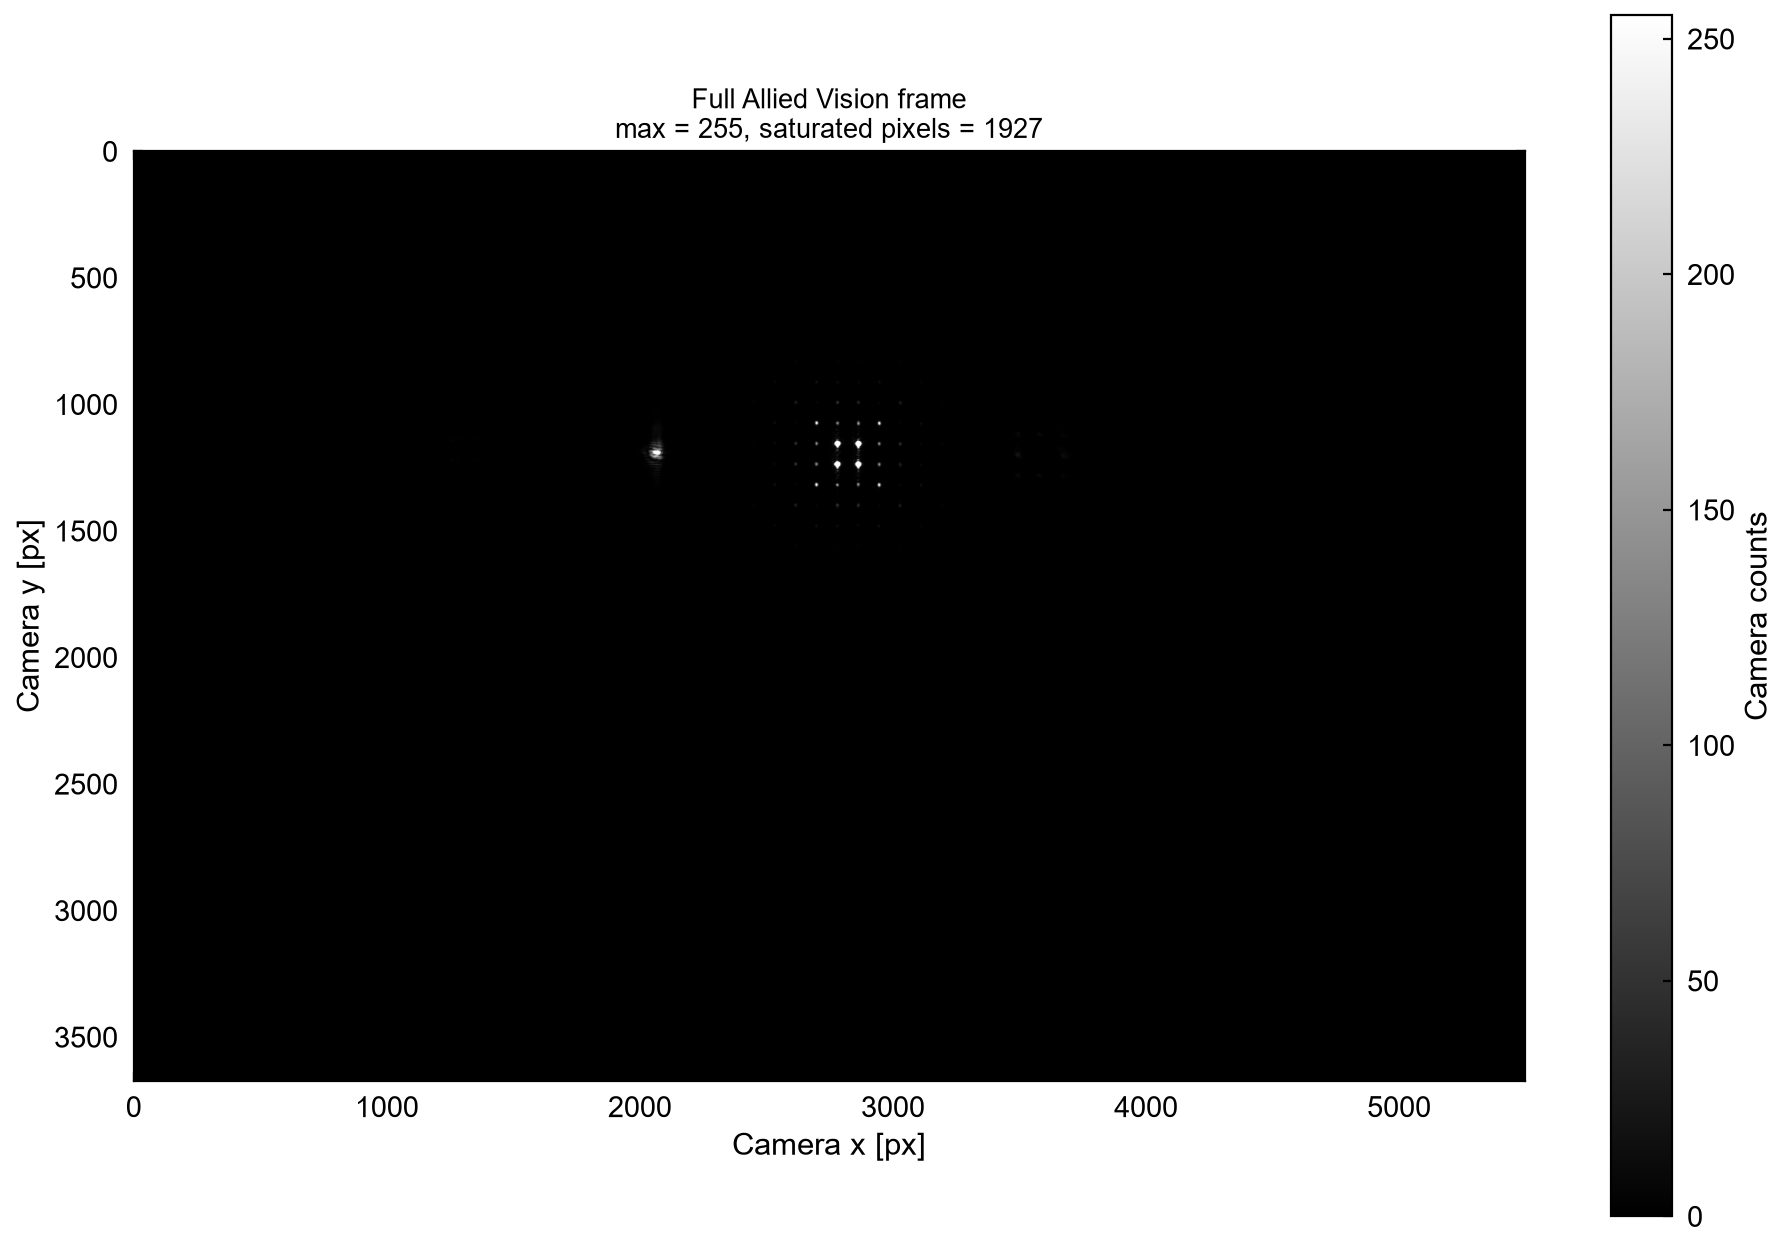

In [19]:
# ============================================================
# VIEW FULL ALLIED VISION IMAGE
# ============================================================

plt.figure(figsize=(12, 8))

plt.imshow(
    img_2x2,
    cmap="gray",
    origin="upper"
)

plt.colorbar(label="Camera counts")

plt.title(
    f"Full Allied Vision frame\n"
    f"max = {img_2x2.max()}, "
    f"saturated pixels = {np.sum(img_2x2 >= 255)}"
)

plt.xlabel("Camera x [px]")
plt.ylabel("Camera y [px]")

plt.tight_layout()
plt.show()

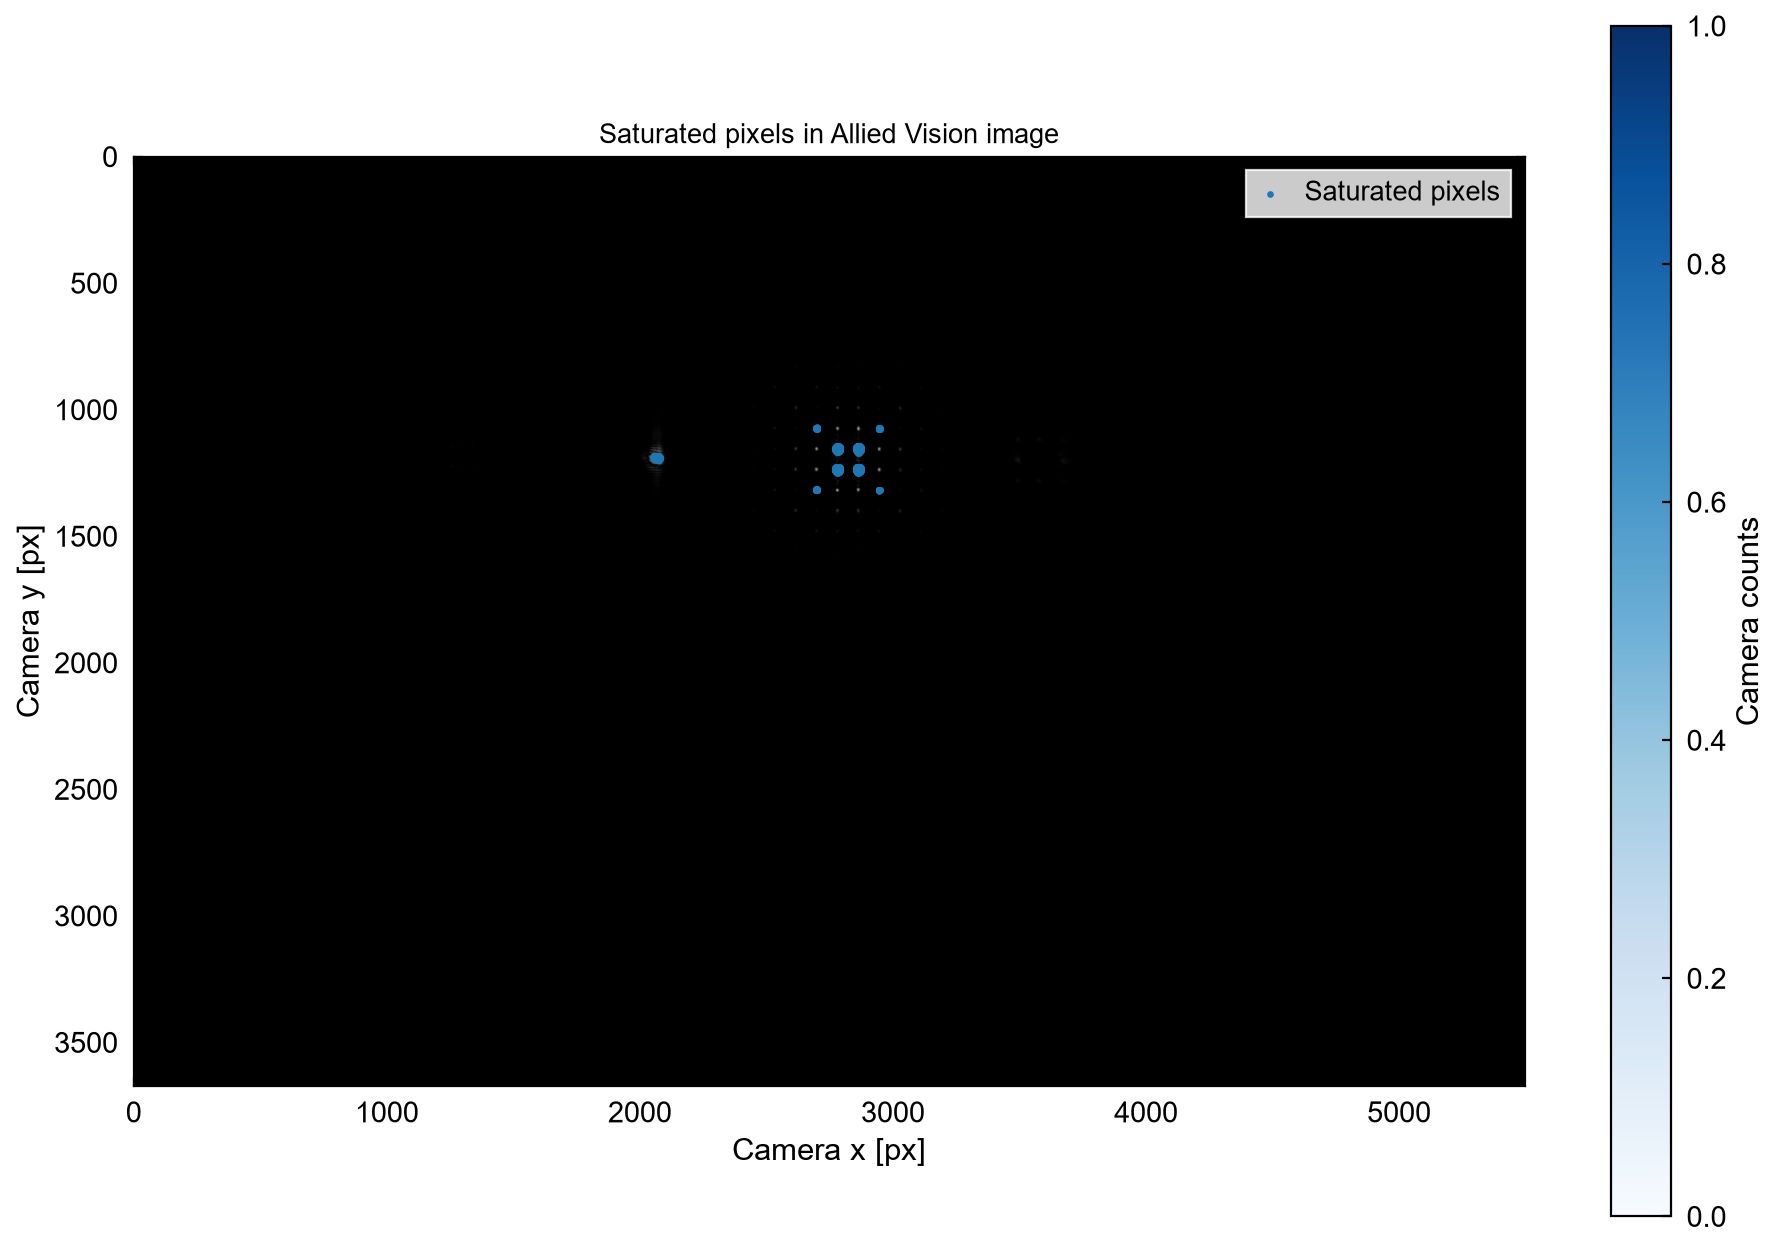

In [20]:
# ============================================================
# FULL IMAGE WITH SATURATED PIXELS MARKED
# ============================================================

sat_y, sat_x = np.where(
    img_2x2 >= 255
)

plt.figure(figsize=(12, 8))

plt.imshow(
    img_2x2,
    cmap="gray",
    origin="upper"
)

plt.scatter(
    sat_x,
    sat_y,
    s=4,
    label="Saturated pixels"
)

plt.colorbar(label="Camera counts")

plt.xlabel("Camera x [px]")
plt.ylabel("Camera y [px]")

plt.title("Saturated pixels in Allied Vision image")

plt.legend()
plt.tight_layout()
plt.show()

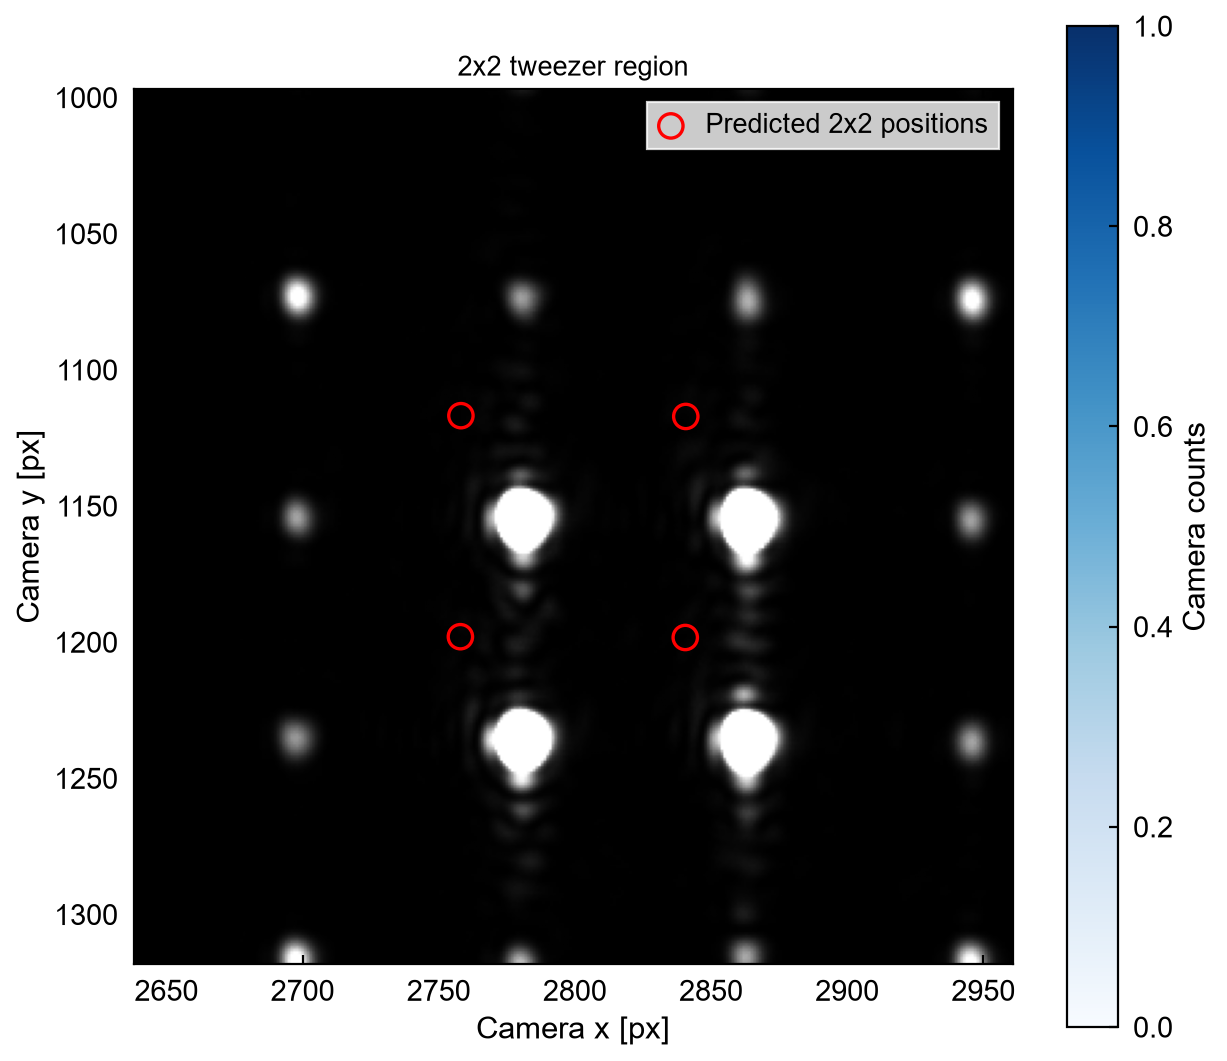

In [21]:
# ============================================================
# ZOOM AROUND THE 2x2 ARRAY
# ============================================================

spots = np.asarray(
    holo_2x2.spot_ij_rounded
)

MARGIN = 120

xmin = spots[0].min() - MARGIN
xmax = spots[0].max() + MARGIN

ymin = spots[1].min() - MARGIN
ymax = spots[1].max() + MARGIN


plt.figure(figsize=(8, 7))

plt.imshow(
    img_2x2,
    cmap="gray",
    origin="upper",
    vmin=0,
    vmax=255
)

plt.scatter(
    spots[0],
    spots[1],
    facecolors="none",
    edgecolors="red",
    s=120,
    linewidths=1.5,
    label="Predicted 2x2 positions"
)

plt.xlim(xmin, xmax)
plt.ylim(ymax, ymin)

plt.colorbar(label="Camera counts")

plt.xlabel("Camera x [px]")
plt.ylabel("Camera y [px]")

plt.title("2x2 tweezer region")

plt.legend()
plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# CHECK SATURATION NEAR EACH TWEEZER
# ============================================================

RADIUS = 10

yy, xx = np.indices(
    img_2x2.shape
)

for i in range(4):

    x = spots[0, i]
    y = spots[1, i]

    rr = np.sqrt(
        (xx - x)**2 +
        (yy - y)**2
    )

    mask = rr <= RADIUS

    local_max = np.max(
        img_2x2[mask]
    )

    local_sat = np.sum(
        img_2x2[mask] >= 255
    )

    print(
        f"Spot {i}: "
        f"max = {local_max}, "
        f"saturated pixels = {local_sat}"
    )

Spot 0: max = 7, saturated pixels = 0
Spot 1: max = 8, saturated pixels = 0
Spot 2: max = 12, saturated pixels = 0
Spot 3: max = 8, saturated pixels = 0


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, maximum_filter


# ============================================================
# FIND THE FOUR ACTUAL SPOTS
# ============================================================

# Region around where the array should be.
# Make this generously large enough to contain both
# prediction and actual spots.
XMIN, XMAX = 2650, 2950
YMIN, YMAX = 1050, 1300

roi = img_2x2[
    YMIN:YMAX,
    XMIN:XMAX
].astype(float)


# Light smoothing for robust peak finding
smooth = gaussian_filter(
    roi,
    sigma=2
)


# Local maxima
local_max = (
    smooth
    ==
    maximum_filter(
        smooth,
        size=35
    )
)


coords = np.argwhere(
    local_max
)


# Sort by brightness
brightness = smooth[
    coords[:, 0],
    coords[:, 1]
]

order = np.argsort(
    brightness
)[::-1]


# Keep four brightest
coords = coords[
    order[:4]
]


# Convert back to full-camera coordinates
actual_y = coords[:, 0] + YMIN
actual_x = coords[:, 1] + XMIN


# Sort top row first, then left/right
pts = np.column_stack([
    actual_x,
    actual_y
])

pts = pts[
    np.argsort(pts[:, 1])
]

top = pts[:2]
bottom = pts[2:]

top = top[
    np.argsort(top[:, 0])
]

bottom = bottom[
    np.argsort(bottom[:, 0])
]

actual_spots = np.vstack([
    top,
    bottom
])


print("Actual spot positions [x, y]:")
print(actual_spots)

Actual spot positions [x, y]:
[[2781 1154]
 [2864 1155]
 [2781 1236]
 [2863 1236]]


In [24]:
# ============================================================
# SUBPIXEL CENTROIDS
# ============================================================

def subpixel_centroid(
    image,
    x_guess,
    y_guess,
    radius=8
):

    x_guess = int(round(x_guess))
    y_guess = int(round(y_guess))

    x1 = x_guess - radius
    x2 = x_guess + radius + 1

    y1 = y_guess - radius
    y2 = y_guess + radius + 1

    crop = image[
        y1:y2,
        x1:x2
    ].astype(float)

    # local background
    bg = np.percentile(
        crop,
        20
    )

    data = crop - bg
    data[data < 0] = 0

    yy, xx = np.indices(
        crop.shape
    )

    total = np.sum(data)

    xc = (
        np.sum(xx * data)
        / total
        + x1
    )

    yc = (
        np.sum(yy * data)
        / total
        + y1
    )

    return xc, yc


actual_sub = []

for x, y in actual_spots:

    xc, yc = subpixel_centroid(
        img_2x2,
        x,
        y,
        radius=8
    )

    actual_sub.append(
        [xc, yc]
    )


actual_sub = np.array(
    actual_sub
)


print("Subpixel actual spot positions:")
print(actual_sub)

Subpixel actual spot positions:
[[nan nan]
 [nan nan]
 [nan nan]
 [nan nan]]


C:\Users\admin\AppData\Local\Temp\ipykernel_18436\1240884757.py:42: RuntimeWarning: invalid value encountered in scalar divide
  np.sum(xx * data)
C:\Users\admin\AppData\Local\Temp\ipykernel_18436\1240884757.py:48: RuntimeWarning: invalid value encountered in scalar divide
  np.sum(yy * data)


In [25]:
pred = np.asarray(
    holo_2x2.spot_ij_rounded
).T

In [26]:
# ============================================================
# MEASURE GLOBAL OFFSET
# ============================================================

pred = np.asarray(
    holo_2x2.spot_ij_rounded
).T


pred_center = np.mean(
    pred,
    axis=0
)

actual_center = np.mean(
    actual_sub,
    axis=0
)


delta = (
    actual_center
    -
    pred_center
)


print("Predicted center [x,y]:")
print(pred_center)

print("\nActual center [x,y]:")
print(actual_center)

print("\nActual - predicted shift [px]:")
print(delta)

Predicted center [x,y]:
[2799.33492288 1157.53158414]

Actual center [x,y]:
[nan nan]

Actual - predicted shift [px]:
[nan nan]


In [27]:
# ============================================================
# ACTUAL ARRAY SPACING
# ============================================================

# Convention:
#
# 0 = top-left
# 1 = top-right
# 2 = bottom-left
# 3 = bottom-right

dx_top = np.linalg.norm(
    actual_sub[1]
    -
    actual_sub[0]
)

dx_bottom = np.linalg.norm(
    actual_sub[3]
    -
    actual_sub[2]
)

dy_left = np.linalg.norm(
    actual_sub[2]
    -
    actual_sub[0]
)

dy_right = np.linalg.norm(
    actual_sub[3]
    -
    actual_sub[1]
)


pitch_x = (
    dx_top + dx_bottom
) / 2

pitch_y = (
    dy_left + dy_right
) / 2


print(
    f"Measured X pitch = "
    f"{pitch_x:.3f} px"
)

print(
    f"Measured Y pitch = "
    f"{pitch_y:.3f} px"
)

print(
    f"Requested pitch = "
    f"{CAMERA_PITCH_PX:.3f} px"
)

Measured X pitch = nan px
Measured Y pitch = nan px
Requested pitch = 77.447 px


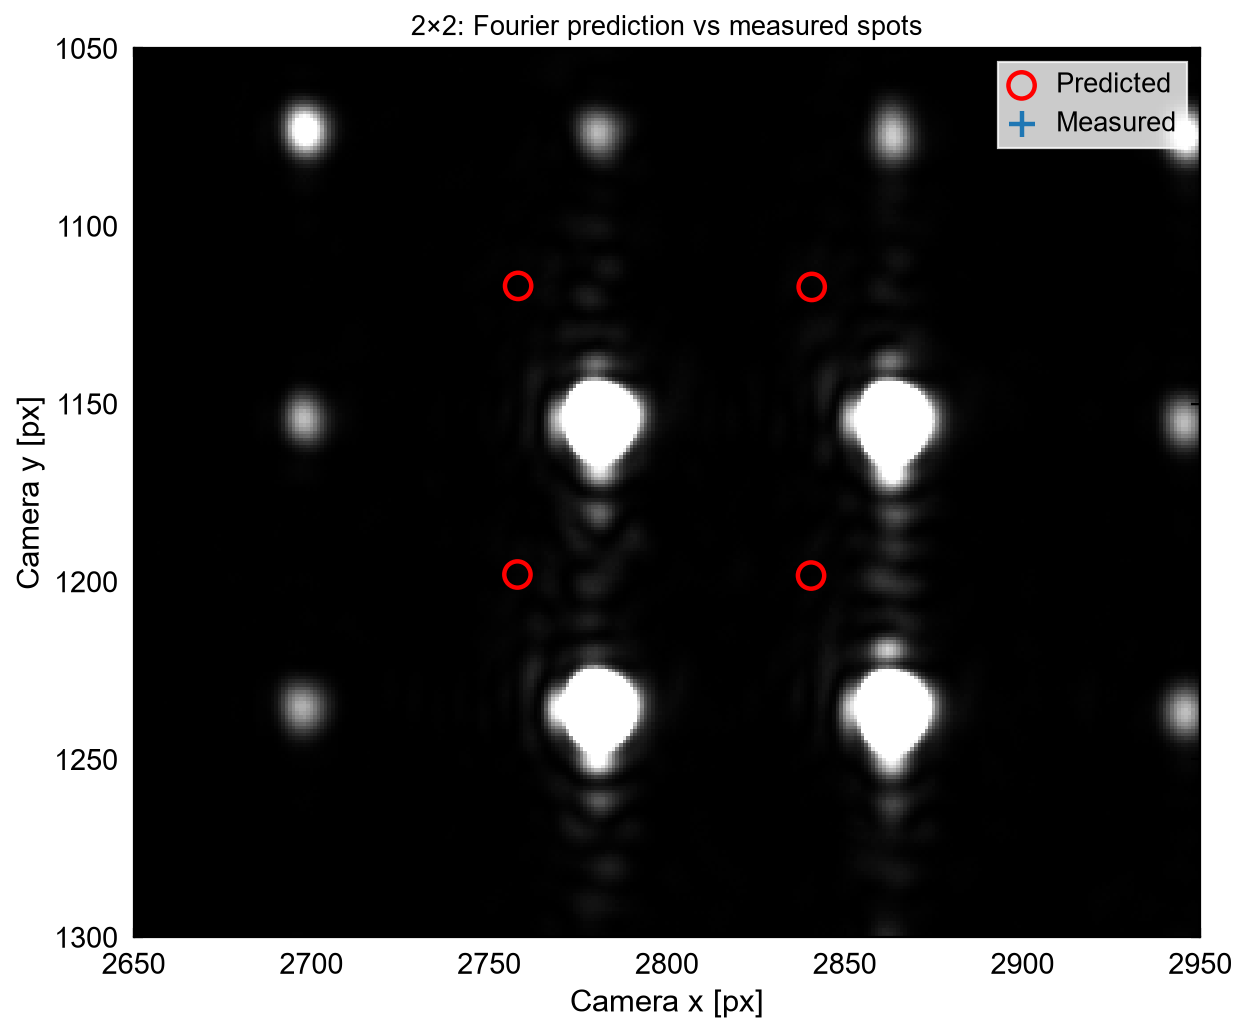

In [28]:
# ============================================================
# OVERLAY ACTUAL AND PREDICTED SPOTS
# ============================================================

plt.figure(figsize=(8, 7))

plt.imshow(
    img_2x2,
    cmap="gray",
    origin="upper",
    vmin=0,
    vmax=min(
        220,
        img_2x2.max()
    )
)


# prediction
plt.scatter(
    pred[:, 0],
    pred[:, 1],
    facecolors="none",
    edgecolors="red",
    s=140,
    linewidths=2,
    label="Predicted"
)


# actual centroids
plt.scatter(
    actual_sub[:, 0],
    actual_sub[:, 1],
    marker="+",
    s=140,
    linewidths=2,
    label="Measured"
)


plt.xlim(
    2650,
    2950
)

plt.ylim(
    1300,
    1050
)

plt.xlabel("Camera x [px]")
plt.ylabel("Camera y [px]")

plt.title(
    "2×2: Fourier prediction vs measured spots"
)

plt.legend()

plt.tight_layout()
plt.show()

In [29]:
ARRAY_CENTER_COMPENSATED = (
    ARRAY_CENTER_IJ
    -
    delta
)


print(
    "Old requested center:",
    ARRAY_CENTER_IJ
)

print(
    "Compensated requested center:",
    ARRAY_CENTER_COMPENSATED
)

Old requested center: [2799.33492288 1157.53158414]
Compensated requested center: [nan nan]


In [30]:
holo_2x2 = SpotHologram.make_rectangular_array(
    shape=(2048, 2048),

    array_shape=(2, 2),

    array_pitch=(
        CAMERA_PITCH_PX,
        CAMERA_PITCH_PX
    ),

    array_center=ARRAY_CENTER_COMPENSATED,

    basis="ij",

    cameraslm=fs,
)

c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\holography\algorithms\_spots.py:1495: RuntimeWarning: invalid value encountered in cast
  self.spot_knm_rounded = np.rint(self.spot_knm).astype(int)


IndexError: index -9223372036854775808 is out of bounds for axis 0 with size 2048

In [ ]:
slm.set_phase(
    holo_2x2.get_phase(),
    phase_correct=True,
    settle=True
)

array([[109,  88, 195, ...,   4, 211,   1],
       [238, 252, 161, ..., 193, 111, 188],
       [251, 153, 206, ...,  56,  51,  70],
       ...,
       [135,  74, 183, ...,  49,  26,  74],
       [110, 163,  95, ...,  40,  26,  66],
       [  6,  47,  90, ...,  74,  44, 136]],
      shape=(1200, 1920), dtype=uint8)

## rebuilding

In [ ]:
# ============================================================
# CORRECT CENTER + X/Y PITCH
# ============================================================

DESIRED_CAMERA_PITCH = CAMERA_PITCH_PX

measured_pitch_x = 82.591
measured_pitch_y = 81.210


scale_x = measured_pitch_x / DESIRED_CAMERA_PITCH
scale_y = measured_pitch_y / DESIRED_CAMERA_PITCH


COMMAND_PITCH_X = (
    DESIRED_CAMERA_PITCH / scale_x
)

COMMAND_PITCH_Y = (
    DESIRED_CAMERA_PITCH / scale_y
)


ARRAY_CENTER_COMPENSATED = np.array([
    2774.65122614,
    1119.85593038
])


print("Scale X:", scale_x)
print("Scale Y:", scale_y)

print(
    "Commanded X pitch:",
    COMMAND_PITCH_X
)

print(
    "Commanded Y pitch:",
    COMMAND_PITCH_Y
)

print(
    "Compensated center:",
    ARRAY_CENTER_COMPENSATED
)

Scale X: 1.066414992
Scale Y: 1.0485835199999998
Commanded X pitch: 72.62401259607206
Commanded Y pitch: 73.85900534813679
Compensated center: [2774.65122614 1119.85593038]


In [ ]:
# ============================================================
# REBUILD CORRECTED 2x2
# ============================================================

holo_2x2_corr = SpotHologram.make_rectangular_array(
    shape=(2048*2, 2048*2),

    array_shape=(9, 9),

    array_pitch=(
        COMMAND_PITCH_X,
        COMMAND_PITCH_Y
    ),

    array_center=ARRAY_CENTER_COMPENSATED,

    basis="ij",

    cameraslm=fs,
)


print("Predicted corrected positions:")
print(
    holo_2x2_corr.spot_ij_rounded
)

Predicted corrected positions:
[[2484.53848806 2555.32230094 2629.05543936 2702.78857778 2773.57239066
  2847.30552907 2921.03866749 2991.82248037 3065.55561879 2484.36182426
  2558.09496267 2628.87877555 2702.61191397 2773.39572685 2847.12886527
  2920.86879844 2991.65261132 3065.38574974 2484.19195521 2557.92509363
  2628.70890651 2702.44204493 2773.22585781 2846.95899622 2920.69213464
  2991.47594752 3065.20908593 2484.01529141 2557.74842982 2628.5322427
  2702.26538112 2775.99851954 2846.78912718 2920.52226559 2991.30607847
  3065.03921689 2483.84542236 2557.57856078 2628.36237366 2702.09551207
  2775.82865049 2846.61246337 2920.34560179 2991.12941467 3064.86255308
  2483.66875856 2557.40189697 2628.18570985 2701.91884827 2775.65198669
  2846.44259433 2920.17573274 2993.90887116 3064.69268404 2483.49888951
  2557.23202793 2628.01584081 2701.74897922 2775.48211764 2846.26593052
  2919.99906894 2993.73220735 3064.51602023 2483.32222571 2557.05536412
  2630.78850254 2701.57231542 2775

In [ ]:
holo_2x2_corr.optimize(
    method="GS",
    maxiter=30,
    verbose=True,
)


phase_corr = (
    holo_2x2_corr.get_phase().copy()
)


slm.set_phase(
    phase_corr,
    phase_correct=True,
    settle=True
)

  0%|          | 0/30 [00:00<?, ?it/s]

array([[ 78,  60,  41, ..., 135, 121, 107],
       [ 80,  61,  43, ..., 138, 124, 111],
       [ 82,  63,  45, ..., 142, 129, 116],
       ...,
       [167, 159, 150, ...,   8, 251, 237],
       [163, 156, 149, ...,  11, 253, 239],
       [158, 153, 147, ...,  13, 255, 241]],
      shape=(1200, 1920), dtype=uint8)

In [ ]:
# ============================================================
# SHRINK ARRAY SPACING FOR 10x10
# ============================================================

# Current corrected pitches correspond to 5 um atom spacing.
#
# A 9x9 array has 8 spacings across.
# A 10x10 array has 9 spacings across.
#
# To keep the same total physical width:
#
# 9 * d_new = 8 * 5 um
#
# d_new = 4.444 um

SPACING_SCALE = 8.6 / 9

COMMAND_PITCH_X_10x10 = COMMAND_PITCH_X * SPACING_SCALE
COMMAND_PITCH_Y_10x10 = COMMAND_PITCH_Y * SPACING_SCALE


print(
    "Old commanded X pitch:",
    COMMAND_PITCH_X
)

print(
    "Old commanded Y pitch:",
    COMMAND_PITCH_Y
)

print()

print(
    "New 10x10 commanded X pitch:",
    COMMAND_PITCH_X_10x10
)

print(
    "New 10x10 commanded Y pitch:",
    COMMAND_PITCH_Y_10x10
)

print()

print(
    "Equivalent atom spacing:",
    5.0 * SPACING_SCALE,
    "um"
)

Old commanded X pitch: 72.62401259607206
Old commanded Y pitch: 73.85900534813679

New 10x10 commanded X pitch: 69.3962787029133
New 10x10 commanded Y pitch: 70.5763828882196

Equivalent atom spacing: 4.777777777777778 um


In [ ]:
# ============================================================
# GENERATE 10x10 ARRAY
# ============================================================

holo_10x10 = SpotHologram.make_rectangular_array(
    shape=(2048*2, 2048*2),

    array_shape=(10, 10),

    array_pitch=(
        COMMAND_PITCH_X_10x10,
        COMMAND_PITCH_Y_10x10
    ),

    array_center=ARRAY_CENTER_COMPENSATED,

    basis="ij",

    cameraslm=fs,
)


print("Predicted 10x10 positions:")
print(
    holo_10x10.spot_ij_rounded
)

Predicted 10x10 positions:
[[2460.9914471  2531.77525998 2602.55907286 2670.3935602  2741.17737308
  2809.01865519 2879.80246807 2947.63695541 3018.42076829 3086.25525564
  2463.77769836 2531.6121857  2602.39599858 2670.23048592 2741.0142988
  2808.84878615 2879.63259903 2947.46708637 3018.25089925 3086.09218135
  2463.60782931 2531.44911142 2602.2329243  2670.06741164 2740.85122452
  2808.68571186 2879.46952474 2947.30401209 3018.08782497 3085.92231231
  2463.44475503 2531.27924237 2602.06305525 2669.8975426  2740.68135548
  2808.52263758 2879.30645046 2947.1409378  3017.92475068 3085.75923803
  2463.28168075 2531.11616809 2601.89998097 2669.73446831 2740.51828119
  2808.35276854 2879.13658142 2946.97106876 3017.75488164 3085.59616374
  2463.1118117  2530.94629905 2601.73690669 2669.57139403 2740.35520691
  2808.18969425 2878.97350713 2946.80799448 3017.59180736 3088.37562024
  2462.94873742 2530.78322476 2601.56703764 2669.40152499 2740.18533787
  2808.01982521 2878.81043285 2949.594

In [ ]:
holo_10x10.optimize(
    method="GS",
    maxiter=20,
    verbose=True
)

phase_10x10 = (
    holo_10x10.get_phase().copy()
)

slm.set_phase(
    phase_10x10,
    phase_correct=True,
    settle=True
)

  0%|          | 0/20 [00:00<?, ?it/s]

array([[ 93,  69,  44, ..., 235, 215, 194],
       [ 98,  73,  48, ..., 237, 217, 195],
       [101,  77,  52, ..., 239, 218, 197],
       ...,
       [134, 116,  99, ...,  65,  44,  25],
       [132, 115,  97, ...,  64,  43,  23],
       [130, 113,  95, ...,  62,  41,  21]],
      shape=(1200, 1920), dtype=uint8)

In [ ]:
# ============================================================
# 10x10 ARRAY, SHIFTED BY ONE COLUMN RELATIVE TO THE
# 16-PIXEL-BLAZE / CARRIER CENTER
# ============================================================

SHIFT_COLUMNS = +2.5

ARRAY_CENTER_SHIFTED = (
    ARRAY_CENTER_COMPENSATED
    + np.array([
        SHIFT_COLUMNS * COMMAND_PITCH_X,
        0.0
    ])
)

print("Original center:")
print(ARRAY_CENTER_COMPENSATED)

print("\nShifted center:")
print(ARRAY_CENTER_SHIFTED)

Original center:
[2774.65122614 1119.85593038]

Shifted center:
[2956.21125763 1119.85593038]


In [ ]:
holo_10x10 = SpotHologram.make_rectangular_array(
    shape=(2048*4, 2048*4),

    array_shape=(10, 10),

    array_pitch=(
        COMMAND_PITCH_X,
        COMMAND_PITCH_Y
    ),

    array_center=ARRAY_CENTER_SHIFTED,

    basis="ij",

    cameraslm=fs,
)

In [ ]:
holo_10x10.optimize(
    method="GS",
    maxiter=20,
    verbose=True
)

phase_10x10 = holo_10x10.get_phase().copy()

slm.set_phase(
    phase_10x10,
    phase_correct=True,
    settle=True
)

  0%|          | 0/20 [00:00<?, ?it/s]

array([[ 42,  16, 248, ...,  49,  34,  20],
       [ 40,  14, 244, ...,  49,  34,  20],
       [ 37,  10, 240, ...,  48,  34,  19],
       ...,
       [ 56,  38,  19, ..., 185, 168, 153],
       [ 52,  33,  14, ..., 184, 166, 149],
       [ 47,  28,   9, ..., 183, 164, 145]],
      shape=(1200, 1920), dtype=uint8)

## WGS on 2.5 shifted 10x10


In [ ]:
# ============================================================
# SAVE CURRENT +2.5 SHIFTED GS SOLUTION
# ============================================================

phase_10x10_GS = holo_10x10.get_phase().copy()
weights_10x10_GS = holo_10x10.get_weights().copy()

print("Saved GS checkpoint.")
print("Number of spots:", holo_10x10.spot_ij.shape[1])
print("Hologram shape :", holo_10x10.shape)
print("Phase shape    :", phase_10x10_GS.shape)

NameError: name 'holo_10x10' is not defined

In [ ]:
# ============================================================
# ACQUIRE CURRENT 10x10 ON ALLIED VISION
# ============================================================

cam.set_exposure(100e-6)

cam.flush()

img_av_GS = cam.get_image()

print("Image shape :", img_av_GS.shape)
print("dtype       :", img_av_GS.dtype)
print("min         :", img_av_GS.min())
print("max         :", img_av_GS.max())
print("mean        :", img_av_GS.mean())
print("bit depth   :", cam.bitdepth)
print("exposure us :", cam.get_exposure() * 1e6)

Image shape : (3672, 5496)
dtype       : uint8
min         : 0
max         : 255
mean        : 0.06255287069542356
bit depth   : 8
exposure us : 112.181
